In [1]:
import numpy as np 
import pandas as pd
import scanpy as sc 
import matplotlib.pyplot as plt
import os 
# save_dir = 'supp_species/analysis'
# os.makedirs(save_dir, exist_ok = True)
from sklearn.preprocessing import minmax_scale

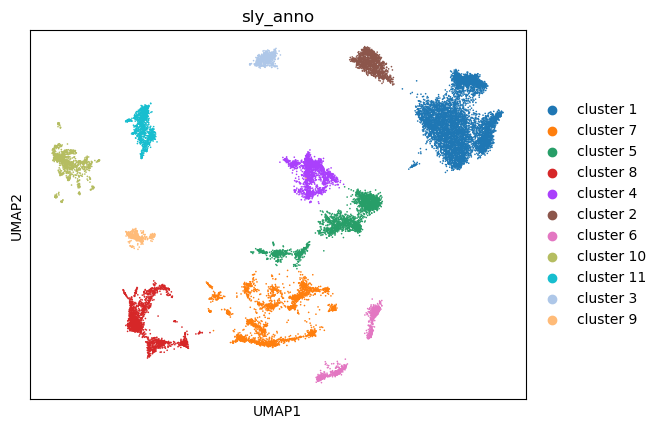

In [2]:
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad') 
sc.pl.umap(scdata, color = 'sly_anno')

In [5]:
df = pd.crosstab(scdata.obs.species, scdata.obs.sly_anno)
df[df.values <= 15] = 0
df.to_csv('counts_multi.csv')

## 五个物种

In [2]:
mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

## re-normalize 
scdata = mdata.copy()
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)


idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'Synpr'].X.toarray()
u = np.percentile(x, 25)

(21723, 9911) (21723, 9911)


### CY

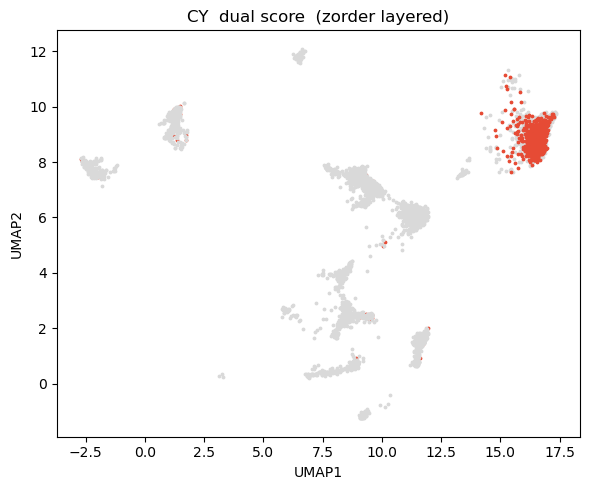

In [3]:
# ============================================================
# 0. 准备物种数据和阈值 (复用 notebook 上方的逻辑)
# ============================================================
species = 'CY'
adata = scdata[scdata.obs.species == species, :].copy()

# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'Pex5l'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'Otof'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'Sox5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

# ============================================================
# 4. 分层可视化
# ============================================================
# 配色
RED   = '#E64B35'      # 暖红，替代纯 red
BLUE  = '#4C72B0'      # 柔和蓝，替代纯 blue
GRAY  = '#D9D9D9'      # 浅灰

mask_c2 = (adata.obs.sly_anno == 'cluster 1').values

x = adata.obsm['X_umap'][:, 0]
y = adata.obsm['X_umap'][:, 1]

score_arr = adata.obs['score'].values
m1 = (score_arr == '1')
m0 = (score_arr == '0')
m_neg1 = (score_arr == '-1')

fig, ax = plt.subplots(figsize=(6, 5))

# ---- 非 cluster 2：红 → 蓝 → 灰（灰盖在最上面）----
mask_non = ~mask_c2
ax.scatter(x[mask_non & m1],     y[mask_non & m1],     s=3, c=RED,  zorder=1, label='score=1')
ax.scatter(x[mask_non & m_neg1], y[mask_non & m_neg1], s=3, c=BLUE, zorder=2, label='score=-1')
ax.scatter(x[mask_non & m0],     y[mask_non & m0],     s=3, c=GRAY, zorder=3, label='score=0')

# ---- cluster 2：红 → 灰 → 蓝（蓝盖在最上面）----
mask_c2_arr = mask_c2
ax.scatter(x[mask_c2_arr & m1],     y[mask_c2_arr & m1],     s=3, c=RED,  zorder=3)
ax.scatter(x[mask_c2_arr & m0],     y[mask_c2_arr & m0],     s=3, c=GRAY, zorder=2)
ax.scatter(x[mask_c2_arr & m_neg1], y[mask_c2_arr & m_neg1], s=3, c=BLUE, zorder=1)

ax.set_title(f'{species}  dual score  (zorder layered)')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')

# # 简洁图例（不重复）
# handles = [
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=RED,  markersize=5, label='c1 (+1)'),
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=BLUE, markersize=5, label='c2 (−1)'),
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=GRAY, markersize=5, label='neutral (0)'),
# ]
# ax.legend(handles=handles, loc='lower right', fontsize=8, markerscale=1.2)

plt.tight_layout()
plt.savefig('CY_delta.pdf', bbox_inches = 'tight', pad_inches = 0.01)
plt.show()

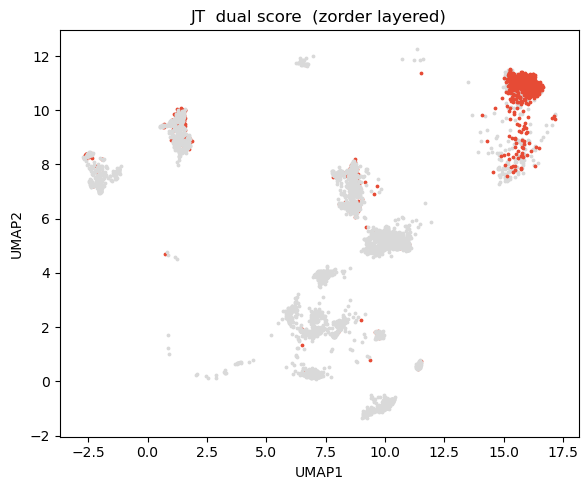

In [5]:
# ============================================================
# 0. 准备物种数据和阈值 (复用 notebook 上方的逻辑)
# ============================================================
species = 'JT'
adata = scdata[scdata.obs.species == species, :].copy()

# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'Pex5l'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'Otof'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'Sox5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

# ============================================================
# 4. 分层可视化
# ============================================================
# 配色
RED   = '#E64B35'      # 暖红，替代纯 red
BLUE  = '#4C72B0'      # 柔和蓝，替代纯 blue
GRAY  = '#D9D9D9'      # 浅灰

mask_c2 = (adata.obs.sly_anno == 'cluster 1').values

x = adata.obsm['X_umap'][:, 0]
y = adata.obsm['X_umap'][:, 1]

score_arr = adata.obs['score'].values
m1 = (score_arr == '1')
m0 = (score_arr == '0')
m_neg1 = (score_arr == '-1')

fig, ax = plt.subplots(figsize=(6, 5))

# ---- 非 cluster 2：红 → 蓝 → 灰（灰盖在最上面）----
mask_non = ~mask_c2
ax.scatter(x[mask_non & m1],     y[mask_non & m1],     s=3, c=RED,  zorder=1, label='score=1')
ax.scatter(x[mask_non & m_neg1], y[mask_non & m_neg1], s=3, c=BLUE, zorder=2, label='score=-1')
ax.scatter(x[mask_non & m0],     y[mask_non & m0],     s=3, c=GRAY, zorder=3, label='score=0')

# ---- cluster 2：红 → 灰 → 蓝（蓝盖在最上面）----
mask_c2_arr = mask_c2
ax.scatter(x[mask_c2_arr & m1],     y[mask_c2_arr & m1],     s=3, c=RED,  zorder=3)
ax.scatter(x[mask_c2_arr & m0],     y[mask_c2_arr & m0],     s=3, c=GRAY, zorder=2)
ax.scatter(x[mask_c2_arr & m_neg1], y[mask_c2_arr & m_neg1], s=3, c=BLUE, zorder=1)

ax.set_title(f'{species}  dual score  (zorder layered)')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')

# # 简洁图例（不重复）
# handles = [
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=RED,  markersize=5, label='c1 (+1)'),
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=BLUE, markersize=5, label='c2 (−1)'),
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=GRAY, markersize=5, label='neutral (0)'),
# ]
# ax.legend(handles=handles, loc='lower right', fontsize=8, markerscale=1.2)
plt.savefig('JT_delta.pdf', bbox_inches = 'tight', pad_inches = 0.01)
plt.tight_layout()
plt.show()

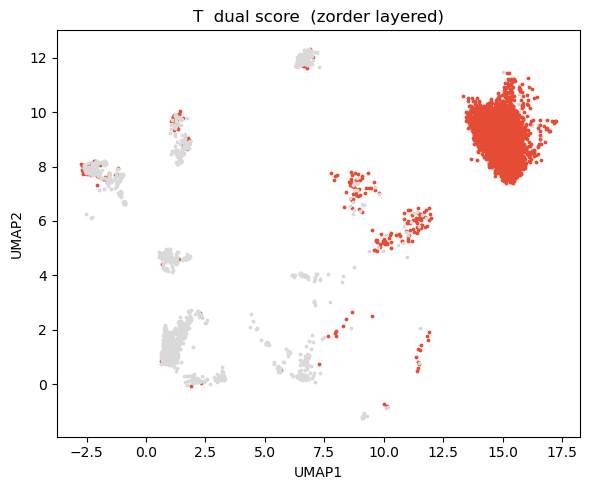

In [6]:
# ============================================================
# 0. 准备物种数据和阈值 (复用 notebook 上方的逻辑)
# ============================================================
species = 'T'
adata = scdata[scdata.obs.species == species, :].copy()

# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'Pex5l'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'Otof'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'Sox5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

# ============================================================
# 4. 分层可视化
# ============================================================
# 配色
RED   = '#E64B35'      # 暖红，替代纯 red
BLUE  = '#4C72B0'      # 柔和蓝，替代纯 blue
GRAY  = '#D9D9D9'      # 浅灰

mask_c2 = (adata.obs.sly_anno == 'cluster 1').values

x = adata.obsm['X_umap'][:, 0]
y = adata.obsm['X_umap'][:, 1]

score_arr = adata.obs['score'].values
m1 = (score_arr == '1')
m0 = (score_arr == '0')
m_neg1 = (score_arr == '-1')

fig, ax = plt.subplots(figsize=(6, 5))

# ---- 非 cluster 2：红 → 蓝 → 灰（灰盖在最上面）----
mask_non = ~mask_c2
ax.scatter(x[mask_non & m1],     y[mask_non & m1],     s=3, c=RED,  zorder=1, label='score=1')
ax.scatter(x[mask_non & m_neg1], y[mask_non & m_neg1], s=3, c=BLUE, zorder=2, label='score=-1')
ax.scatter(x[mask_non & m0],     y[mask_non & m0],     s=3, c=GRAY, zorder=3, label='score=0')

# ---- cluster 2：红 → 灰 → 蓝（蓝盖在最上面）----
mask_c2_arr = mask_c2
ax.scatter(x[mask_c2_arr & m1],     y[mask_c2_arr & m1],     s=3, c=RED,  zorder=3)
ax.scatter(x[mask_c2_arr & m0],     y[mask_c2_arr & m0],     s=3, c=GRAY, zorder=2)
ax.scatter(x[mask_c2_arr & m_neg1], y[mask_c2_arr & m_neg1], s=3, c=BLUE, zorder=1)

ax.set_title(f'{species}  dual score  (zorder layered)')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')

# # 简洁图例（不重复）
# handles = [
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=RED,  markersize=5, label='c1 (+1)'),
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=BLUE, markersize=5, label='c2 (−1)'),
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=GRAY, markersize=5, label='neutral (0)'),
# ]
# ax.legend(handles=handles, loc='lower right', fontsize=8, markerscale=1.2)

plt.tight_layout()
plt.savefig('T_delta.pdf', bbox_inches = 'tight', pad_inches = 0.01)
plt.show()

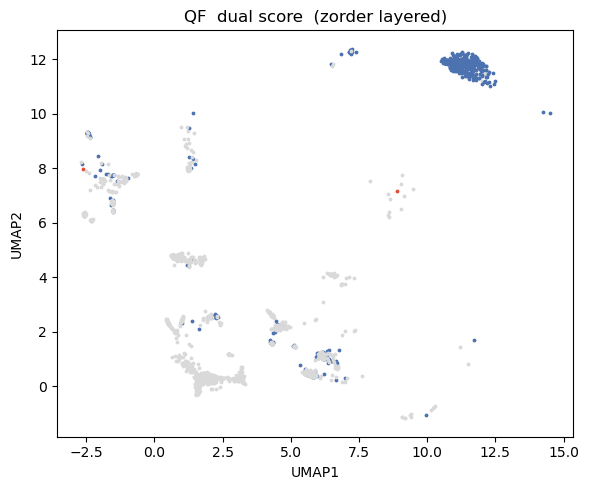

In [7]:
# ============================================================
# 0. 准备物种数据和阈值 (复用 notebook 上方的逻辑)
# ============================================================
species = 'QF'
adata = scdata[scdata.obs.species == species, :].copy()

# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'Pex5l'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'Otof'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'Sox5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

# ============================================================
# 4. 分层可视化
# ============================================================
# 配色
RED   = '#E64B35'      # 暖红，替代纯 red
BLUE  = '#4C72B0'      # 柔和蓝，替代纯 blue
GRAY  = '#D9D9D9'      # 浅灰

mask_c2 = (adata.obs.sly_anno == 'cluster 2').values

x = adata.obsm['X_umap'][:, 0]
y = adata.obsm['X_umap'][:, 1]

score_arr = adata.obs['score'].values
m1 = (score_arr == '1')
m0 = (score_arr == '0')
m_neg1 = (score_arr == '-1')

fig, ax = plt.subplots(figsize=(6, 5))

# ---- 非 cluster 2：红 → 蓝 → 灰（灰盖在最上面）----
mask_non = ~mask_c2
ax.scatter(x[mask_non & m1],     y[mask_non & m1],     s=3, c=RED,  zorder=1, label='score=1')
ax.scatter(x[mask_non & m_neg1], y[mask_non & m_neg1], s=3, c=BLUE, zorder=2, label='score=-1')
ax.scatter(x[mask_non & m0],     y[mask_non & m0],     s=3, c=GRAY, zorder=3, label='score=0')

# ---- cluster 2：红 → 灰 → 蓝（蓝盖在最上面）----
mask_c2_arr = mask_c2
ax.scatter(x[mask_c2_arr & m1],     y[mask_c2_arr & m1],     s=3, c=RED,  zorder=1)
ax.scatter(x[mask_c2_arr & m0],     y[mask_c2_arr & m0],     s=3, c=GRAY, zorder=2)
ax.scatter(x[mask_c2_arr & m_neg1], y[mask_c2_arr & m_neg1], s=3, c=BLUE, zorder=3)

ax.set_title(f'{species}  dual score  (zorder layered)')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')

# # 简洁图例（不重复）
# handles = [
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=RED,  markersize=5, label='c1 (+1)'),
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=BLUE, markersize=5, label='c2 (−1)'),
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=GRAY, markersize=5, label='neutral (0)'),
# ]
# ax.legend(handles=handles, loc='lower right', fontsize=8, markerscale=1.2)

plt.tight_layout()
plt.savefig('QF_delta.pdf', bbox_inches = 'tight', pad_inches = 0.01)
plt.show()

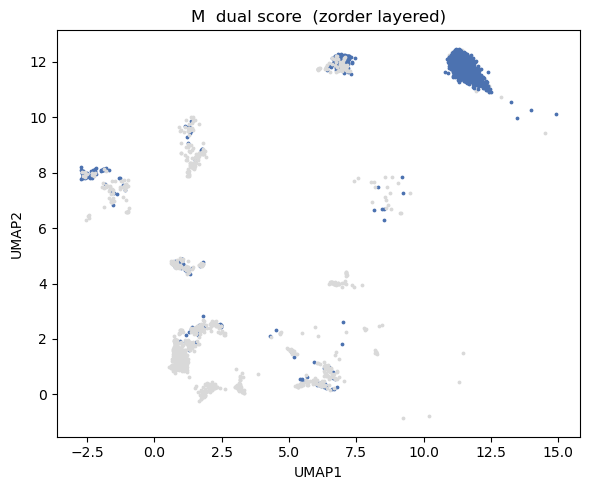

In [8]:
# ============================================================
# 0. 准备物种数据和阈值 (复用 notebook 上方的逻辑)
# ============================================================
species = 'M'
adata = scdata[scdata.obs.species == species, :].copy()

# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'Pex5l'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'Otof'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'Csmd1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'Sox5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'Synpr'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

# ============================================================
# 4. 分层可视化
# ============================================================
# 配色
RED   = '#E64B35'      # 暖红，替代纯 red
BLUE  = '#4C72B0'      # 柔和蓝，替代纯 blue
GRAY  = '#D9D9D9'      # 浅灰

mask_c2 = (adata.obs.sly_anno == 'cluster 2').values

x = adata.obsm['X_umap'][:, 0]
y = adata.obsm['X_umap'][:, 1]

score_arr = adata.obs['score'].values
m1 = (score_arr == '1')
m0 = (score_arr == '0')
m_neg1 = (score_arr == '-1')

fig, ax = plt.subplots(figsize=(6, 5))

# ---- 非 cluster 2：红 → 蓝 → 灰（灰盖在最上面）----
mask_non = ~mask_c2
ax.scatter(x[mask_non & m1],     y[mask_non & m1],     s=3, c=RED,  zorder=1, label='score=1')
ax.scatter(x[mask_non & m_neg1], y[mask_non & m_neg1], s=3, c=BLUE, zorder=2, label='score=-1')
ax.scatter(x[mask_non & m0],     y[mask_non & m0],     s=3, c=GRAY, zorder=3, label='score=0')

# ---- cluster 2：红 → 灰 → 蓝（蓝盖在最上面）----
mask_c2_arr = mask_c2
ax.scatter(x[mask_c2_arr & m1],     y[mask_c2_arr & m1],     s=3, c=RED,  zorder=1)
ax.scatter(x[mask_c2_arr & m0],     y[mask_c2_arr & m0],     s=3, c=GRAY, zorder=2)
ax.scatter(x[mask_c2_arr & m_neg1], y[mask_c2_arr & m_neg1], s=3, c=BLUE, zorder=3)

ax.set_title(f'{species}  dual score  (zorder layered)')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')

plt.tight_layout()
plt.savefig('M_delta.pdf', bbox_inches = 'tight', pad_inches = 0.01)
plt.show()

## Dog

In [9]:
## load ref data 

mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()
new_var = [ele.upper() for ele in scdata.var.index]
scdata.var.index = new_var

## load query data
adata = sc.read_h5ad('../supp_species/dog_ex_neu.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)

## synpr threchold
idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'SYNPR'].X.toarray()
u = np.percentile(x, 25)
print(f'synpr threshold {u}')

## load query data
# adata = sc.read_h5ad('supp_species/dog_ex_neu.h5ad')
species = 'dog'

# idx_1 = adata[:,'SYNPR'].X.toarray() >= u
# idx_2 = adata[:,'OTOF'].X.toarray() > 0 
# idx_3 = adata[:,'CSMD1'].X.toarray() == 0
# idx_4 = adata[:,'PEX5L'].X.toarray() == 0 

# idx = (idx_1 | idx_2) & idx_3 & idx_4

# if idx.sum() <= 5:
#     idx[:5] = True 
# adata.obs.loc[:,'c1_idx'] = idx.astype(str)
# adata.obs.c1_idx = adata.obs.c1_idx.astype('category')

# sc.tl.embedding_density(adata, groupby = 'c1_idx')
# ax = sc.pl.embedding_density(
#     adata, basis='umap', key='umap_density_c1_idx', 
#     bg_dotsize=3, fg_dotsize= 3, color_map = 'coolwarm', 
#     group = 'True',show = False)
# plt.savefig(f'{species}_score.pdf',bbox_inches = 'tight')

(21723, 9911) (21723, 9911)
mutual gene number 8819


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


synpr threshold 2.226362109184265


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


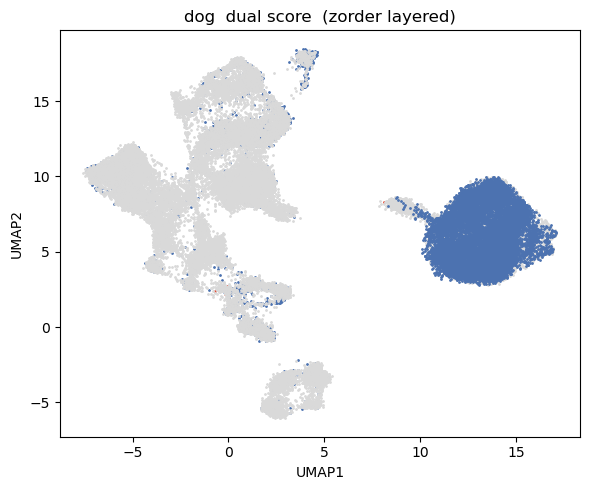

In [10]:
# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'PEX5L'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'OTOF'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'SOX5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

# ============================================================
# 4. 分层可视化
# ============================================================
# 配色
RED   = '#E64B35'      # 暖红，替代纯 red
BLUE  = '#4C72B0'      # 柔和蓝，替代纯 blue
GRAY  = '#D9D9D9'      # 浅灰

mask_c2 = (adata.obs.sr_anno.isin(['0','8'])).values # 'cluster 2').values

x = adata.obsm['X_umap'][:, 0]
y = adata.obsm['X_umap'][:, 1]

score_arr = adata.obs['score'].values
m1 = (score_arr == '1')
m0 = (score_arr == '0')
m_neg1 = (score_arr == '-1')

fig, ax = plt.subplots(figsize=(6, 5))

# ---- 非 cluster 2：红 → 蓝 → 灰（灰盖在最上面）----
mask_non = ~mask_c2
ax.scatter(x[mask_non & m1],     y[mask_non & m1],     s=1, c=RED,  zorder=1, label='score=1')
ax.scatter(x[mask_non &m_neg1], y[mask_non &m_neg1], s=1, c=BLUE, zorder=2, label='score=-1')
ax.scatter(x[mask_non & m0],     y[mask_non &m0],     s=1, c=GRAY, zorder=3, label='score=0')

# # ---- cluster 2：红 → 灰 → 蓝（蓝盖在最上面）----
mask_c2_arr = mask_c2
ax.scatter(x[mask_c2_arr & m1],     y[mask_c2_arr & m1],     s=1, c=RED,  zorder=1)
ax.scatter(x[mask_c2_arr & m0],     y[mask_c2_arr & m0],     s=1, c=GRAY, zorder=2)
ax.scatter(x[mask_c2_arr & m_neg1], y[mask_c2_arr & m_neg1], s=1, c=BLUE, zorder=3)

ax.set_title(f'{species}  dual score  (zorder layered)')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')

plt.tight_layout()
plt.savefig('dog_delta.pdf', bbox_inches = 'tight', pad_inches = 0.01)
plt.show()

## Human

In [9]:
## load ref data 

mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()
new_var = [ele.upper() for ele in scdata.var.index]
scdata.var.index = new_var

## load query data
adata = sc.read_h5ad('../supp_species/human_ex_neu_filter.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)

## synpr threchold
idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'SYNPR'].X.toarray()
u = np.percentile(x, 25)
print(f'synpr threshold {u}')

(21723, 9911) (21723, 9911)
mutual gene number 9855


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


synpr threshold 2.1745232343673706


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


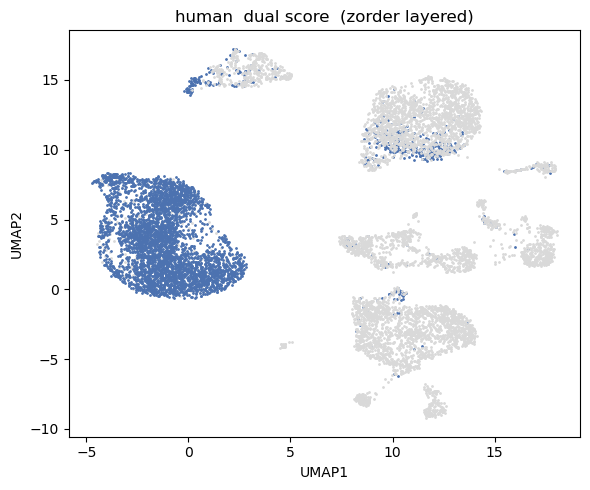

In [10]:
species = 'human'
# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'PEX5L'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'OTOF'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'SOX5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

# ============================================================
# 4. 分层可视化
# ============================================================
# 配色
RED   = '#E64B35'      # 暖红，替代纯 red
BLUE  = '#4C72B0'      # 柔和蓝，替代纯 blue
GRAY  = '#D9D9D9'      # 浅灰

mask_c2 = (adata.obs.sr_anno.isin(['0','3'])).values # 'cluster 2').values

x = adata.obsm['X_umap'][:, 0]
y = adata.obsm['X_umap'][:, 1]

score_arr = adata.obs['score'].values
m1 = (score_arr == '1')
m0 = (score_arr == '0')
m_neg1 = (score_arr == '-1')

fig, ax = plt.subplots(figsize=(6, 5))

# ---- 非 cluster 2：红 → 蓝 → 灰（灰盖在最上面）----
mask_non = ~mask_c2
ax.scatter(x[mask_non & m1],     y[mask_non & m1],     s=1, c=RED,  zorder=1, label='score=1')
ax.scatter(x[mask_non &m_neg1], y[mask_non &m_neg1], s=1, c=BLUE, zorder=2, label='score=-1')
ax.scatter(x[mask_non & m0],     y[mask_non &m0],     s=1, c=GRAY, zorder=3, label='score=0')

# # ---- cluster 2：红 → 灰 → 蓝（蓝盖在最上面）----
mask_c2_arr = mask_c2 #np.array([True]*adata.n_obs)
ax.scatter(x[mask_c2_arr & m1],     y[mask_c2_arr & m1],     s=1, c=RED,  zorder=1)
ax.scatter(x[mask_c2_arr & m0],     y[mask_c2_arr & m0],     s=1, c=GRAY, zorder=2)
ax.scatter(x[mask_c2_arr & m_neg1], y[mask_c2_arr & m_neg1], s=1, c=BLUE, zorder=3)

ax.set_title(f'{species}  dual score  (zorder layered)')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')

plt.tight_layout()
plt.savefig('human_delta.pdf', bbox_inches = 'tight', pad_inches = 0.01)
plt.show()

## Rhesus Macaque

In [13]:
## load ref data 

mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()
new_var = [ele.upper() for ele in scdata.var.index]
scdata.var.index = new_var

## load query data
adata = sc.read_h5ad('../supp_species/mihou_ex_neu.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)

## synpr threchold
idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'SYNPR'].X.toarray()
u = np.percentile(x, 25)
print(f'synpr threshold {u}')

(21723, 9911) (21723, 9911)
mutual gene number 8394


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


synpr threshold 2.249342679977417


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


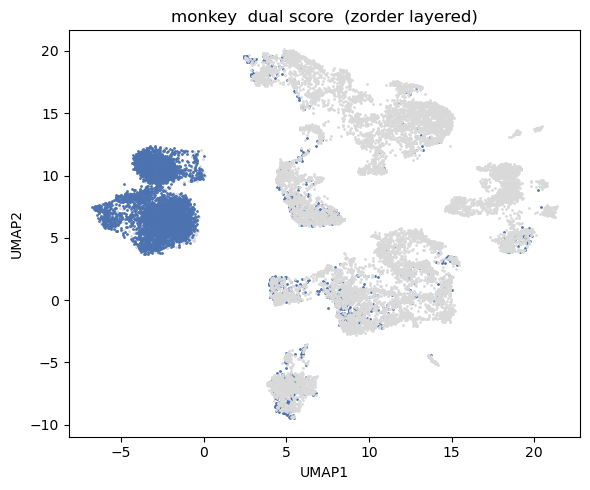

In [14]:
species = 'monkey'
# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'PEX5L'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'OTOF'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'SOX5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

# ============================================================
# 4. 分层可视化
# ============================================================
# 配色
RED   = '#E64B35'      # 暖红，替代纯 red
BLUE  = '#4C72B0'      # 柔和蓝，替代纯 blue
GRAY  = '#D9D9D9'      # 浅灰

mask_c2 = (adata.obs.sr_anno.isin(['0','3'])).values # 'cluster 2').values

x = adata.obsm['X_umap'][:, 0]
y = adata.obsm['X_umap'][:, 1]

score_arr = adata.obs['score'].values
m1 = (score_arr == '1')
m0 = (score_arr == '0')
m_neg1 = (score_arr == '-1')

fig, ax = plt.subplots(figsize=(6, 5))

# ---- 非 cluster 2：红 → 蓝 → 灰（灰盖在最上面）----
mask_non = ~mask_c2
ax.scatter(x[mask_non & m1],     y[mask_non & m1],     s=1, c=RED,  zorder=1, label='score=1')
ax.scatter(x[mask_non &m_neg1], y[mask_non &m_neg1], s=1, c=BLUE, zorder=2, label='score=-1')
ax.scatter(x[mask_non & m0],     y[mask_non &m0],     s=1, c=GRAY, zorder=3, label='score=0')

# # ---- cluster 2：红 → 灰 → 蓝（蓝盖在最上面）----
mask_c2_arr = mask_c2 #np.array([True]*adata.n_obs)
ax.scatter(x[mask_c2_arr & m1],     y[mask_c2_arr & m1],     s=1, c=RED,  zorder=1)
ax.scatter(x[mask_c2_arr & m0],     y[mask_c2_arr & m0],     s=1, c=GRAY, zorder=2)
ax.scatter(x[mask_c2_arr & m_neg1], y[mask_c2_arr & m_neg1], s=1, c=BLUE, zorder=3)

ax.set_title(f'{species}  dual score  (zorder layered)')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')

plt.tight_layout()
plt.savefig('monkey_delta.pdf', bbox_inches = 'tight', pad_inches = 0.01)
plt.show()

## Axolotl

In [15]:
## load ref data 

mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()
new_var = [ele.upper() for ele in scdata.var.index]
scdata.var.index = new_var

## load query data
adata = sc.read_h5ad('../supp_species/dunkouyuan_ex_neu.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)

## synpr threchold
idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'SYNPR'].X.toarray()
u = np.percentile(x, 25)
print(f'synpr threshold {u}')

(21723, 9911) (21723, 9911)
mutual gene number 8465


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


synpr threshold 2.2419021129608154


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


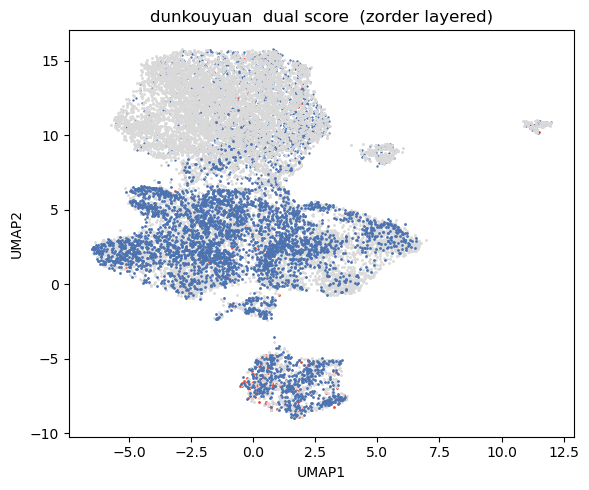

In [16]:
species = 'dunkouyuan'
# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'PEX5L'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'OTOF'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'SOX5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

# ============================================================
# 4. 分层可视化
# ============================================================
# 配色
RED   = '#E64B35'      # 暖红，替代纯 red
BLUE  = '#4C72B0'      # 柔和蓝，替代纯 blue
GRAY  = '#D9D9D9'      # 浅灰

mask_c2 = (adata.obs.sr_anno.isin(['1','3','4','5','6'])).values # 'cluster 2').values

x = adata.obsm['X_umap'][:, 0]
y = adata.obsm['X_umap'][:, 1]

score_arr = adata.obs['score'].values
m1 = (score_arr == '1')
m0 = (score_arr == '0')
m_neg1 = (score_arr == '-1')

fig, ax = plt.subplots(figsize=(6, 5))

# ---- 非 cluster 2：红 → 蓝 → 灰（灰盖在最上面）----
mask_non = ~mask_c2 #np.array([True]*adata.n_obs) #~mask_c2
ax.scatter(x[mask_non & m1],     y[mask_non & m1],     s=1, c=RED,  zorder=1, label='score=1')
ax.scatter(x[mask_non &m_neg1], y[mask_non &m_neg1], s=0.5, c=BLUE, zorder=2, label='score=-1')
ax.scatter(x[mask_non & m0],     y[mask_non &m0],     s=1.2, c=GRAY, zorder=3, label='score=0')

# # ---- cluster 2：红 → 灰 → 蓝（蓝盖在最上面）----
mask_c2_arr = mask_c2 #np.array([True]*adata.n_obs) #mask_c2 #np.array([True]*adata.n_obs)
ax.scatter(x[mask_c2_arr & m1],     y[mask_c2_arr & m1],     s=1, c=RED,  zorder=1)
ax.scatter(x[mask_c2_arr & m0],     y[mask_c2_arr & m0],     s=1, c=GRAY, zorder=2)
ax.scatter(x[mask_c2_arr & m_neg1], y[mask_c2_arr & m_neg1], s=1, c=BLUE, zorder=3)

ax.set_title(f'{species}  dual score  (zorder layered)')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')

plt.tight_layout()
plt.savefig('dunkouyuan_delta.pdf', bbox_inches = 'tight', pad_inches = 0.01)
plt.show()

## Chinese tree shrew

In [11]:
## load ref data 

mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()
new_var = [ele.upper() for ele in scdata.var.index]
scdata.var.index = new_var

## load query data
adata = sc.read_h5ad('../supp_species/shuqu_ex_neu.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)

## synpr threchold
idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'SYNPR'].X.toarray()
u = np.percentile(x, 25)
print(f'synpr threshold {u}')

(21723, 9911) (21723, 9911)
mutual gene number 8259


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


synpr threshold 2.2653262615203857


In [19]:
sample_list = []
for ele in adata.obs.index:
    sample_list.append(ele.split('|')[0])
adata.obs.loc[:,'sample_id'] = sample_list 
adata.obs.sample_id.value_counts()
adata = adata[adata.obs.sample_id == 'TS1']

/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


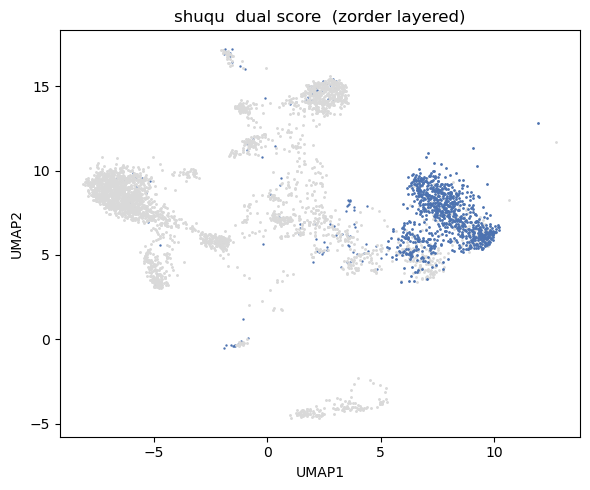

In [20]:
species = 'shuqu'
# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata[:, 'PEX5L'].X.toarray().ravel() == 0
idx_c1_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > u
idx_c1_otof   = adata[:, 'OTOF'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata[:, 'CSMD1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata[:, 'SOX5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata[:, 'SYNPR'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

# ============================================================
# 4. 分层可视化
# ============================================================
# 配色
RED   = '#E64B35'      # 暖红，替代纯 red
BLUE  = '#4C72B0'      # 柔和蓝，替代纯 blue
GRAY  = '#D9D9D9'      # 浅灰

mask_c2 = (adata.obs.sr_anno.isin(['1','0','9'])).values # 'cluster 2').values

x = adata.obsm['X_umap'][:, 0]
y = adata.obsm['X_umap'][:, 1]

score_arr = adata.obs['score'].values
m1 = (score_arr == '1')
m0 = (score_arr == '0')
m_neg1 = (score_arr == '-1')

fig, ax = plt.subplots(figsize=(6, 5))

# ---- 非 cluster 2：红 → 蓝 → 灰（灰盖在最上面）----
mask_non = ~mask_c2
ax.scatter(x[mask_non & m1],     y[mask_non & m1],     s=1, c=RED,  zorder=1, label='score=1')
ax.scatter(x[mask_non &m_neg1], y[mask_non &m_neg1], s=0.5, c=BLUE, zorder=2, label='score=-1')
ax.scatter(x[mask_non & m0],     y[mask_non &m0],     s=1.2, c=GRAY, zorder=3, label='score=0')

# # ---- cluster 2：红 → 灰 → 蓝（蓝盖在最上面）----
mask_c2_arr = mask_c2 #np.array([True]*adata.n_obs)
ax.scatter(x[mask_c2_arr & m1],     y[mask_c2_arr & m1],     s=1, c=RED,  zorder=1)
ax.scatter(x[mask_c2_arr & m0],     y[mask_c2_arr & m0],     s=1, c=GRAY, zorder=2)
ax.scatter(x[mask_c2_arr & m_neg1], y[mask_c2_arr & m_neg1], s=1, c=BLUE, zorder=3)

ax.set_title(f'{species}  dual score  (zorder layered)')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')

plt.tight_layout()
plt.savefig('shuqu_delta.pdf', bbox_inches = 'tight', pad_inches = 0.01)
plt.show()

## Corn Snake

In [19]:
## load ref data 

mdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data_supp/multi_raw.h5ad')
scdata = sc.read_h5ad('../../sly_data/sly_12_large_modify/multi_modify.h5ad')
mdata = mdata[scdata.obs.index,scdata.var.index]
mdata.obs = scdata.obs.copy()

print(mdata.shape, scdata.shape)
mdata.obsm['X_umap'] = scdata.obsm['X_umap']

scdata = mdata.copy()
new_var = [ele.upper() for ele in scdata.var.index]
scdata.var.index = new_var

## load query data
adata = sc.read_h5ad('../supp_species/snake_ex_neu.h5ad') 

## set mutual gene 
mutual_gene = np.intersect1d(scdata.var.index, adata.var.index)
scdata = scdata[:, mutual_gene]
adata = adata[:, mutual_gene]
print(f'mutual gene number {len(mutual_gene)}')

## re-normalize 
sc.pp.normalize_total(scdata, target_sum= 1e4)
sc.pp.log1p(scdata)

## synpr threchold
idx = scdata.obs.sly_anno == 'cluster 1'
x = scdata[idx,'SYNPR'].X.toarray()
u = np.percentile(x, 25)
print(f'synpr threshold {u}')


# ## query new pca 
# sc.pp.h

(21723, 9911) (21723, 9911)
mutual gene number 8450


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


synpr threshold 2.2415720224380493


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/preprocessing/_pca.py:314: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = X_pca
/tmp/ipykernel_950765/597219319.py:15: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution = 0.1)


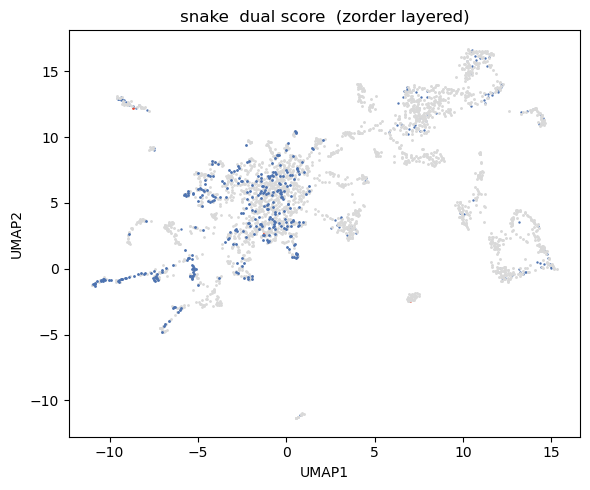

In [20]:
species = 'snake'
adata = sc.read_h5ad('../supp_species/snake_ex_neu.h5ad')
species = 'snake'
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

adata.raw = adata
sc.pp.highly_variable_genes(adata, n_top_genes=3000)
adata = adata[:,adata.var.highly_variable]

sc.tl.pca(adata)
sc.pp.neighbors(adata)

sc.tl.umap(adata, min_dist = 0.5)
sc.tl.leiden(adata, resolution = 0.1)
# ============================================================
# 1. 计算 idx_c1 (Pos-like / cluster 1 标记)
# ============================================================
idx_c1_pex5l  = adata.raw[:, 'PEX5L'].X.toarray().ravel() == 0
idx_c1_synpr  = adata.raw[:, 'SYNPR'].X.toarray().ravel() > u
idx_c1_otof   = adata.raw[:, 'OTOF'].X.toarray().ravel() > 0
idx_c1_csmd1  = adata.raw[:, 'CSMD1'].X.toarray().ravel() == 0

idx_c1 = idx_c1_pex5l & (idx_c1_synpr | idx_c1_otof) & idx_c1_csmd1

# ============================================================
# 2. 计算 idx_c2 (Neg-like / cluster 2 标记)
# ============================================================
idx_c2_csmd1  = adata.raw[:, 'CSMD1'].X.toarray().ravel() > 0
idx_c2_sox5   = adata.raw[:, 'SOX5'].X.toarray().ravel() == 0
idx_c2_synpr  = adata.raw[:, 'SYNPR'].X.toarray().ravel() > 0

idx_c2 = idx_c2_csmd1 & idx_c2_sox5 & idx_c2_synpr



# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

# ============================================================
# 4. 分层可视化
# ============================================================
# 配色
RED   = '#E64B35'      # 暖红，替代纯 red
BLUE  = '#4C72B0'      # 柔和蓝，替代纯 blue
GRAY  = '#D9D9D9'      # 浅灰

mask_c2 = (adata.obs.leiden.isin(['3','0'])).values # 'cluster 2').values

x = adata.obsm['X_umap'][:, 0]
y = adata.obsm['X_umap'][:, 1]

score_arr = adata.obs['score'].values
m1 = (score_arr == '1')
m0 = (score_arr == '0')
m_neg1 = (score_arr == '-1')

fig, ax = plt.subplots(figsize=(6, 5))

# ---- 非 cluster 2：红 → 蓝 → 灰（灰盖在最上面）----
mask_non = ~mask_c2
ax.scatter(x[mask_non & m1],     y[mask_non & m1],     s=1, c=RED,  zorder=1, label='score=1')
ax.scatter(x[mask_non &m_neg1], y[mask_non &m_neg1], s=0.5, c=BLUE, zorder=2, label='score=-1')
ax.scatter(x[mask_non & m0],     y[mask_non &m0],     s=1.2, c=GRAY, zorder=3, label='score=0')

# # ---- cluster 2：红 → 灰 → 蓝（蓝盖在最上面）----
mask_c2_arr = mask_c2 #np.array([True]*adata.n_obs)
ax.scatter(x[mask_c2_arr & m1],     y[mask_c2_arr & m1],     s=1, c=RED,  zorder=1)
ax.scatter(x[mask_c2_arr & m0],     y[mask_c2_arr & m0],     s=1, c=GRAY, zorder=2)
ax.scatter(x[mask_c2_arr & m_neg1], y[mask_c2_arr & m_neg1], s=1, c=BLUE, zorder=3)

ax.set_title(f'{species}  dual score  (zorder layered)')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')

plt.tight_layout()
plt.savefig('snake_delta.pdf', bbox_inches = 'tight', pad_inches = 0.01)
plt.show()

## zebrafish

In [ ]:
scdata = sc.read_h5ad('../supp_species/banmayu_ex_neu.h5ad') 

adata = scdata.copy()
species = 'banmayu'
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
sc.pp.highly_variable_genes(adata, n_top_genes=3000)
adata = adata[:,adata.var.highly_variable]
sc.tl.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata, min_dist = 0.5)

In [ ]:
idx_1 = adata.raw[:,'SYNPR'].X.toarray() >= 2
idx_2 = adata.raw[:,'OTOF'].X.toarray() > 0 
# idx_3 = adata.raw[:,'CSMD1'].X.toarray() == 0
idx_4 = adata.raw[:,'PEX5L'].X.toarray() == 0 
idx_c1 = ((idx_1 | idx_2)  & idx_4).ravel() #& idx_3

# idx_1 = adata.raw[:,'CSMD1'].X.toarray() > 0 
idx_2 = adata.raw[:,'SOX5'].X.toarray() == 0
idx_3 = adata.raw[:,'SYNPR'].X.toarray() > 0 
idx_c2 = (idx_2 & idx_3).ravel() #idx_1 & idx_2 & idx_3 


# ============================================================
# 3. 计算 dual density score
# ============================================================
adata.obs.loc[:,'score'] = '0'
adata.obs.loc[idx_c1, 'score'] = '1'
adata.obs.loc[idx_c2, 'score'] = '-1'

# ============================================================
# 4. 分层可视化
# ============================================================
# 配色
RED   = '#E64B35'      # 暖红，替代纯 red
BLUE  = '#4C72B0'      # 柔和蓝，替代纯 blue
GRAY  = '#D9D9D9'      # 浅灰

# mask_c2 = (adata.obs.leiden.isin(['3','0'])).values # 'cluster 2').values

x = adata.obsm['X_umap'][:, 0]
y = adata.obsm['X_umap'][:, 1]

score_arr = adata.obs['score'].values
m1 = (score_arr == '1')
m0 = (score_arr == '0')
m_neg1 = (score_arr == '-1')

fig, ax = plt.subplots(figsize=(6, 5))

# ---- 非 cluster 2：红 → 蓝 → 灰（灰盖在最上面）----
mask_non = np.array([True]*adata.n_obs) #~mask_c2
ax.scatter(x[mask_non & m1],     y[mask_non & m1],     s=1, c=RED,  zorder=1, label='score=1')
ax.scatter(x[mask_non &m_neg1], y[mask_non &m_neg1], s=1, c=BLUE, zorder=2, label='score=-1')
ax.scatter(x[mask_non & m0],     y[mask_non &m0],     s=1.2, c=GRAY, zorder=3, label='score=0')

ax.set_title(f'{species}  dual score  (zorder layered)')
ax.set_xlabel('UMAP1')
ax.set_ylabel('UMAP2')

plt.tight_layout()
plt.savefig('banmayu_delta.pdf', bbox_inches = 'tight', pad_inches = 0.01)
plt.show()